# 01 - Data Exploration 

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle
from matplotlib.ticker import PercentFormatter

In [2]:
df = pd.read_parquet('../data/interim/shots.parquet')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2525326 entries, 0 to 2525325
Data columns (total 25 columns):
 #   Column               Dtype  
---  ------               -----  
 0   GRID_TYPE            str    
 1   GAME_ID              str    
 2   GAME_EVENT_ID        int64  
 3   PLAYER_ID            int64  
 4   PLAYER_NAME          str    
 5   TEAM_ID              int64  
 6   TEAM_NAME            str    
 7   PERIOD               int64  
 8   MINUTES_REMAINING    int64  
 9   SECONDS_REMAINING    int64  
 10  EVENT_TYPE           str    
 11  ACTION_TYPE          str    
 12  SHOT_TYPE            str    
 13  SHOT_ZONE_BASIC      str    
 14  SHOT_ZONE_AREA       str    
 15  SHOT_ZONE_RANGE      str    
 16  SHOT_DISTANCE        float64
 17  LOC_X                float64
 18  LOC_Y                float64
 19  SHOT_ATTEMPTED_FLAG  int64  
 20  SHOT_MADE_FLAG       int64  
 21  GAME_DATE            str    
 22  HTM                  str    
 23  VTM                  str    
 24  SEASON   

In [4]:
df.head()

,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM,SEASON
0,Shot Chart Detail,0021400008,5,2594,Kyle Korver,1610612737,Atlanta Hawks,1,11,7,...,24+ ft.,22.0,228.0,4.0,1,1,20141029,TOR,ATL,2014-15
1,Shot Chart Detail,0021400008,8,200794,Paul Millsap,1610612737,Atlanta Hawks,1,10,36,...,Less Than 8 ft.,5.0,-10.0,58.0,1,0,20141029,TOR,ATL,2014-15
2,Shot Chart Detail,0021400008,12,201952,Jeff Teague,1610612737,Atlanta Hawks,1,10,13,...,Less Than 8 ft.,1.0,10.0,7.0,1,0,20141029,TOR,ATL,2014-15
3,Shot Chart Detail,0021400008,14,201143,Al Horford,1610612737,Atlanta Hawks,1,10,6,...,16-24 ft.,17.0,176.0,11.0,1,0,20141029,TOR,ATL,2014-15
4,Shot Chart Detail,0021400008,17,201143,Al Horford,1610612737,Atlanta Hawks,1,9,35,...,8-16 ft.,10.0,6.0,105.0,1,0,20141029,TOR,ATL,2014-15


In [5]:
df[df["PLAYER_NAME"] == "Stephen Curry"].head(10)

,GRID_TYPE,GAME_ID,GAME_EVENT_ID,PLAYER_ID,PLAYER_NAME,TEAM_ID,TEAM_NAME,PERIOD,MINUTES_REMAINING,SECONDS_REMAINING,...,SHOT_ZONE_RANGE,SHOT_DISTANCE,LOC_X,LOC_Y,SHOT_ATTEMPTED_FLAG,SHOT_MADE_FLAG,GAME_DATE,HTM,VTM,SEASON
48442,Shot Chart Detail,0021400014,50,201939,Stephen Curry,1610612744,Golden State Warriors,1,7,29,...,8-16 ft.,10.0,-81.0,72.0,1,1,20141029,SAC,GSW,2014-15
48446,Shot Chart Detail,0021400014,74,201939,Stephen Curry,1610612744,Golden State Warriors,1,5,9,...,24+ ft.,25.0,65.0,246.0,1,0,20141029,SAC,GSW,2014-15
48459,Shot Chart Detail,0021400014,176,201939,Stephen Curry,1610612744,Golden State Warriors,2,8,49,...,Less Than 8 ft.,2.0,23.0,15.0,1,1,20141029,SAC,GSW,2014-15
48460,Shot Chart Detail,0021400014,205,201939,Stephen Curry,1610612744,Golden State Warriors,2,6,43,...,Less Than 8 ft.,1.0,-11.0,7.0,1,1,20141029,SAC,GSW,2014-15
48463,Shot Chart Detail,0021400014,227,201939,Stephen Curry,1610612744,Golden State Warriors,2,5,36,...,24+ ft.,24.0,-164.0,187.0,1,0,20141029,SAC,GSW,2014-15
48464,Shot Chart Detail,0021400014,238,201939,Stephen Curry,1610612744,Golden State Warriors,2,4,59,...,8-16 ft.,10.0,-4.0,102.0,1,0,20141029,SAC,GSW,2014-15
48470,Shot Chart Detail,0021400014,305,201939,Stephen Curry,1610612744,Golden State Warriors,2,1,6,...,8-16 ft.,8.0,-78.0,34.0,1,0,20141029,SAC,GSW,2014-15
48476,Shot Chart Detail,0021400014,349,201939,Stephen Curry,1610612744,Golden State Warriors,3,10,18,...,24+ ft.,23.0,-229.0,26.0,1,0,20141029,SAC,GSW,2014-15
48479,Shot Chart Detail,0021400014,378,201939,Stephen Curry,1610612744,Golden State Warriors,3,8,2,...,24+ ft.,25.0,-54.0,246.0,1,0,20141029,SAC,GSW,2014-15
48485,Shot Chart Detail,0021400014,431,201939,Stephen Curry,1610612744,Golden State Warriors,3,4,26,...,24+ ft.,24.0,-18.0,246.0,1,1,20141029,SAC,GSW,2014-15


In [6]:
eda = df[df["SEASON"] !="2025-26"]
eda.shape[1]

25

In [7]:
# FG% and volume by zone
(eda.groupby("SHOT_ZONE_BASIC")["SHOT_MADE_FLAG"]
    .agg(fg_pct="mean", shots="size")
    .sort_values("shots", ascending=False)
    .round(3))

,fg_pct,shots
SHOT_ZONE_BASIC,,
Restricted Area,0.635,711940
Above the Break 3,0.352,620779
In The Paint (Non-RA),0.420,393200
Mid-Range,0.405,374183
Left Corner 3,0.386,104257
Right Corner 3,0.387,96580
Backcourt,0.023,4866


In [ ]:
FIG_DIR = "../reports/figures"
SEASONS_LABEL = "NBA regular seasons 2014-15 to 2024-25"

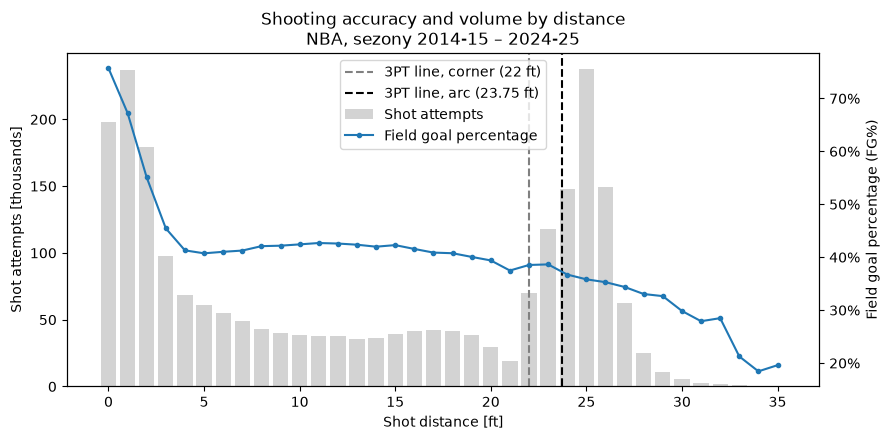

In [17]:
d = eda[eda["SHOT_DISTANCE"] <= 35].groupby("SHOT_DISTANCE")["SHOT_MADE_FLAG"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(d.index, d["size"] / 1000, color="lightgray", label="Shot attempts")
ax.axvline(22, color="gray", linestyle="--", label="3PT line, corner (22 ft)")
ax.axvline(23.75, color="black", linestyle="--", label="3PT line, arc (23.75 ft)")
ax.set_xlabel("Shot distance [ft]")
ax.set_ylabel("Shot attempts [thousands]")

ax2 = ax.twinx()
ax2.plot(d.index, d["mean"], color="tab:blue", marker="o", ms=3, label="Field goal percentage")
ax2.set_ylabel("Field goal percentage (FG%)")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper center")
ax.set_title(f"Shooting accuracy and volume by distance\n{SEASONS_LABEL}")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fg_pct_by_distance.pdf")
plt.show()

In [19]:
def draw_court(ax, color="black", lw=1):
    """Half court in feet, hoop at (0, 0), baseline at y = -5.25."""
    ax.add_patch(Circle((0, 0), 0.75, fill=False, color=color, lw=lw))           # rim
    ax.plot([-3, 3], [-1.25, -1.25], color=color, lw=lw)                          # backboard
    ax.plot([-8, -8, 8, 8], [-5.25, 13.75, 13.75, -5.25], color=color, lw=lw)     # paint
    ax.plot([-22, -22], [-5.25, 8.95], color=color, lw=lw)                        # corner 3
    ax.plot([22, 22], [-5.25, 8.95], color=color, lw=lw)
    ax.add_patch(Arc((0, 0), 47.5, 47.5, theta1=22.1, theta2=157.9, color=color, lw=lw))  # 3PT arc
    ax.plot([-25, 25], [-5.25, -5.25], color=color, lw=lw) 

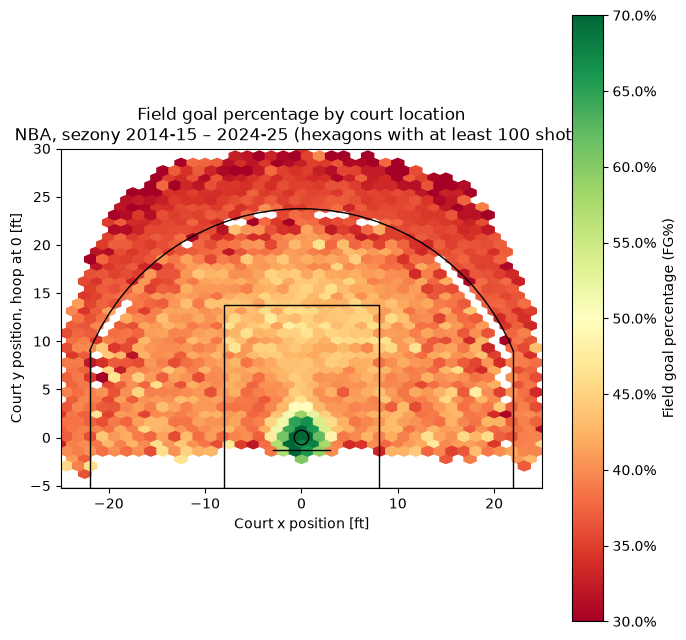

In [20]:
# Shot map: FG% per hexagon (LOC_X/LOC_Y in tenths of feet, hoop at 0,0)
half = eda[eda["LOC_Y"] < 300]
fig, ax = plt.subplots(figsize=(7, 6.5))
hb = ax.hexbin(half["LOC_X"] / 10, half["LOC_Y"] / 10, C=half["SHOT_MADE_FLAG"],
               reduce_C_function=np.mean, gridsize=40, mincnt=100, cmap="RdYlGn",
               extent=(-25, 25, -5.25, 30), vmin=0.3, vmax=0.7)
cb = fig.colorbar(hb, ax=ax, format=PercentFormatter(1.0))
cb.set_label("Field goal percentage (FG%)")
draw_court(ax)
ax.set_xlim(-25, 25)
ax.set_ylim(-5.25, 30)
ax.set_aspect("equal")
ax.set_xlabel("Court x position [ft]")
ax.set_ylabel("Court y position, hoop at 0 [ft]")
ax.set_title(f"Field goal percentage by court location\n{SEASONS_LABEL} (hexagons with at least 100 shots)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/shot_map_fg_pct.pdf")
plt.show()